In [1]:
import cheetah
import torch

In [2]:
segment = cheetah.Segment(
    elements=[
        cheetah.Drift(length=torch.tensor(0.175)),
        cheetah.Quadrupole(length=torch.tensor(0.122), name="AREAMQZM1"),
        cheetah.Drift(length=torch.tensor(0.428)),
        cheetah.Quadrupole(length=torch.tensor(0.122), name="AREAMQZM2"),
        cheetah.Drift(length=torch.tensor(0.204)),
        cheetah.VerticalCorrector(length=torch.tensor(0.02), name="AREAMCVM1"),
        cheetah.Drift(length=torch.tensor(0.204)),
        cheetah.Quadrupole(length=torch.tensor(0.122), name="AREAMQZM3"),
        cheetah.Drift(length=torch.tensor(0.179)),
        cheetah.HorizontalCorrector(length=torch.tensor(0.02), name="AREAMCHM1"),
        cheetah.Drift(length=torch.tensor(0.45)),
        cheetah.Screen(name="AREABSCR1"),
    ]
)

In [3]:
segment.AREAMQZM1.k1 = torch.tensor(8.2)
segment.AREAMQZM2.k1 = torch.tensor(-14.3)
segment.AREAMCVM1.angle = torch.tensor(9e-5)
segment.AREAMQZM3.k1 = torch.tensor(3.142)
segment.AREAMCHM1.angle = torch.tensor(-1e-4)

In [4]:
parameter_beam = cheetah.ParameterBeam.from_twiss(beta_x=torch.tensor(3.14))
particle_beam = cheetah.ParticleBeam.from_twiss(
    beta_x=torch.tensor(3.14), beta_y=torch.tensor(42.0), num_particles=10_000
)

In [5]:
outgoing_beam = segment.track(parameter_beam)

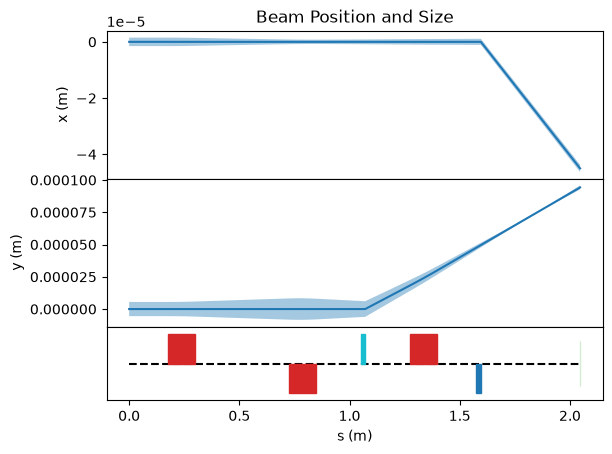

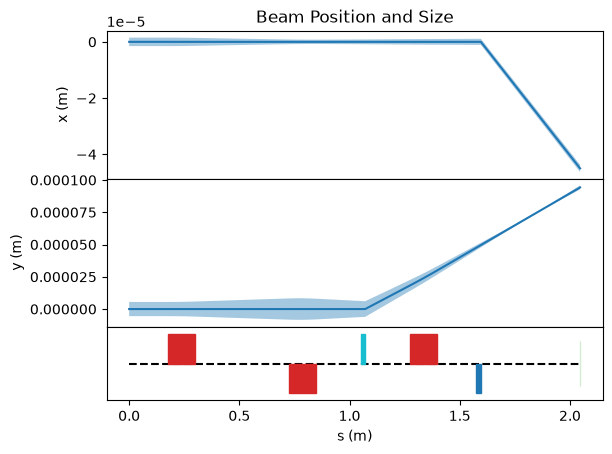

In [6]:
segment.plot_overview(incoming=particle_beam, resolution=0.05)

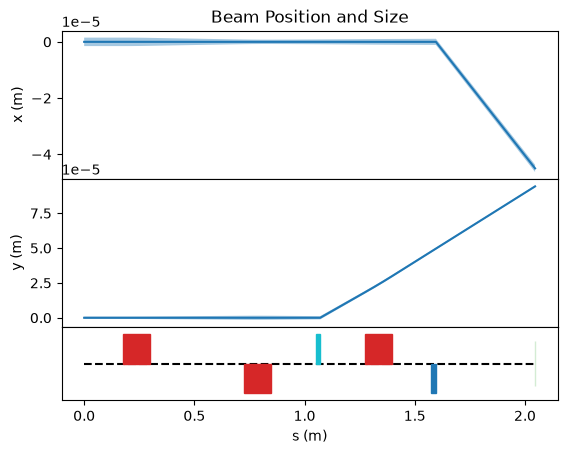

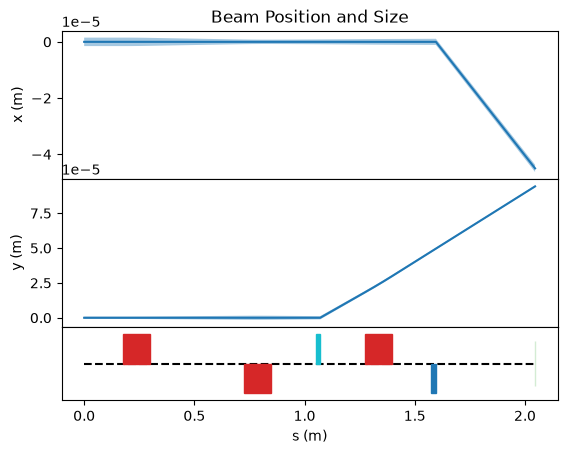

In [7]:
segment.plot_overview(incoming=parameter_beam, resolution=0.05)